In [56]:
import numpy as np
from scipy.io import loadmat
from scipy.linalg import eigvalsh

#inoput 

mat_file_path = "../data/10 Agents/p5/Set1.mat"
n_functions = 10
seed = 20260629

#function distance weight

w_theta = 0.5
w_gamma = 0.5

#min eig value (for making gamm pd)
eig_floor = 1.0

#noise std to inject

noise_homogeneous = 0.1
noise_heterogeneous = 1.0
noise_separated = 0.1

In [57]:
data = loadmat(mat_file_path)


theta_pool = np.stack([
    np.asarray(theta, dtype=float).reshape(-1)
    for theta in data["theta"].ravel()
])

# already PSD
Gamma_pool = np.stack([
    np.asarray(Gamma, dtype=float)
    for Gamma in data["Phi"].ravel()
])

n_pool, dimension = theta_pool.shape

print("Number of candidate functions:", n_pool)
print("Dimension:", dimension)
print("theta_pool shape:", theta_pool.shape)
print("Gamma_pool shape:", Gamma_pool.shape)

Number of candidate functions: 10
Dimension: 5
theta_pool shape: (10, 5)
Gamma_pool shape: (10, 5, 5)


In [ ]:
# make gamma PD

def make_spd(Gamma):
    Gamma = 0.5 * (Gamma + Gamma.T)

    min_eig = np.min(np.linalg.eigvalsh(Gamma))
    shift = max(0.0, eig_floor - min_eig + 1e-10) ## just shifting the eigenvalue if needed

    return Gamma + shift * np.eye(Gamma.shape[0])


# Using Affine riemannian distance between two SPD matrix
def gamma_distance(Gamma_i, Gamma_j):
    eigvalues = eigvalsh(Gamma_i, Gamma_j)

    return np.linalg.norm(np.log(eigvalues))


theta_distances = []
gamma_distances = []

for i in range(n_pool):
    for j in range(i + 1, n_pool):
        theta_distances.append(
            np.linalg.norm(theta_pool[i] - theta_pool[j])
        )

        gamma_distances.append(
            gamma_distance(Gamma_pool[i], Gamma_pool[j])
        )

# compute the mean pairwise distance of the functions in the pool
# use them for normalizing when generating the cluster function

s_theta = max(np.mean(theta_distances), 1e-12)
s_gamma = max(np.mean(gamma_distances), 1e-12)


# print(s_theta, s_gamma)

In [59]:
# compute the functional distance between two functions 
# each function will present by the (theta,gamma) pair -> similar function <=> small distance

def function_distance(theta_i, Gamma_i, theta_j, Gamma_j):
    d_theta = np.linalg.norm(theta_i - theta_j) / s_theta
    d_gamma = gamma_distance(Gamma_i, Gamma_j) / s_gamma

    return w_theta * d_theta + w_gamma * d_gamma

In [60]:
#compute the pool distance matrix and select the medoid
# the medoif is the function that has the msalles total distance to other functions

D_pool = np.zeros((n_pool, n_pool))

for i in range(n_pool):
    for j in range(i + 1, n_pool):
        distance = function_distance(
            theta_pool[i], Gamma_pool[i],
            theta_pool[j], Gamma_pool[j]
        )

        D_pool[i, j] = distance
        D_pool[j, i] = distance

# Select the candidate with the smallest total distance
total_distances = np.sum(D_pool, axis=1) # just compute the total distance for each function in the pool

medoid_index = np.argmin(total_distances) # get the one that has the smallest total distance to other functions in the pool

theta_medoid = theta_pool[medoid_index].copy()
Gamma_medoid = Gamma_pool[medoid_index].copy()

## 1. Generate the Heterogeneous Cluster Function

In [61]:
def sample_function(theta_center, gamma_center, noise, rng):
    theta = theta_center + noise * rng.normal(size=theta_center.shape)

    A = rng.normal(size=gamma_center.shape)
    Gamma_noise = noise * 0.5 * (A + A.T) # addding noise to the sample gamma matrix

    # make psd
    Gamma = make_spd(gamma_center + Gamma_noise)
    return theta, Gamma



In [62]:
## generate the heterogeneous
rng = np.random.default_rng(seed)

theta_heterogeneous = np.zeros((n_functions, dimension))
Gamma_heterogeneous = np.zeros(
    (n_functions, dimension, dimension)
)

for i in range(n_functions):
    theta_heterogeneous[i], Gamma_heterogeneous[i] = sample_function(
        theta_medoid,
        Gamma_medoid,
        noise_heterogeneous,
        rng
    )

print("theta shape:", theta_heterogeneous.shape)
print("Gamma shape:", Gamma_heterogeneous.shape)

theta shape: (10, 5)
Gamma shape: (10, 5, 5)


In [63]:
import json

data_heterogeneous = {
    "theta_list": theta_heterogeneous.tolist(),
    "gamma_list": Gamma_heterogeneous.tolist(),
    "labels": [0] * n_functions
}

# save to the files
with open("heterogeneous.json", "w") as file:
    json.dump(data_heterogeneous, file, indent=2)

## 2. Homogeneous data

In [64]:
## generate the homogeneous

import json

rng = np.random.default_rng(seed)

theta_homogeneous = np.zeros((n_functions, dimension))
Gamma_homogeneous = np.zeros(
    (n_functions, dimension, dimension)
)

for i in range(n_functions):
    theta_homogeneous[i], Gamma_homogeneous[i] = sample_function(
        theta_medoid,
        Gamma_medoid,
        noise_homogeneous,
        rng
    )


data_homogeneous = {
    "theta_list": theta_homogeneous.tolist(),
    "gamma_list": Gamma_homogeneous.tolist(),
    "labels": [0] * n_functions
}

with open("homogeneous.json", "w") as file:
    json.dump(data_homogeneous, file, indent=2)

## 3. Seperate clusters

In [65]:
separation_alpha = 0.5
max_attempts = 20000

# select the prototype function for the separate cluster
# using the two function that has the largest distance in the pool
prototype_indices_2 = np.array(
    np.unravel_index(np.argmax(D_pool), D_pool.shape)
)

theta_prototypes_2 = theta_pool[prototype_indices_2].copy()
Gamma_prototypes_2 = Gamma_pool[prototype_indices_2].copy()

delta_2 = D_pool[
    prototype_indices_2[0],
    prototype_indices_2[1]
]

radius_2 = separation_alpha * delta_2 / 2

print("Prototype indices:", prototype_indices_2)
print("Prototype distance:", delta_2)
print("Sampling radius:", radius_2)

Prototype indices: [2 7]
Prototype distance: 1.314745634314881
Sampling radius: 0.3286864085787202


In [66]:
## generate and save the separate cluster
K = 2
rng = np.random.default_rng(seed)

# set the cluster sizes for the separate cluster
cluster_sizes_2 = np.full(K, n_functions // K)
cluster_sizes_2[:n_functions % K] += 1

labels_separated_2 = np.repeat(np.arange(K), cluster_sizes_2)

theta_separated_2 = np.zeros((n_functions, dimension))
Gamma_separated_2 = np.zeros(
    (n_functions, dimension, dimension)
)

# sampling for each function for each cluster
for i, k in enumerate(labels_separated_2):
    for attempt in range(max_attempts):
        theta, Gamma = sample_function(
            theta_prototypes_2[k],
            Gamma_prototypes_2[k],
            noise_separated,
            rng
        )

        distance = function_distance(
            theta, Gamma,
            theta_prototypes_2[k], Gamma_prototypes_2[k]
        )

        if distance <= radius_2:
            theta_separated_2[i] = theta
            Gamma_separated_2[i] = Gamma
            break

data_separated_2 = {
    "theta_list": theta_separated_2.tolist(),
    "gamma_list": Gamma_separated_2.tolist(),
    "labels": labels_separated_2.tolist()
}

with open("separated_2_clusters.json", "w") as file:
    json.dump(data_separated_2, file, indent=2)

print("Cluster sizes:", cluster_sizes_2)
print("theta shape:", theta_separated_2.shape)
print("Gamma shape:", Gamma_separated_2.shape)

Cluster sizes: [5 5]
theta shape: (10, 5)
Gamma shape: (10, 5, 5)


## Separate Clusters K = 3

In [67]:
# Distance from each candidate to its nearest selected prototype
nearest_distances = np.min(
    D_pool[:, prototype_indices_2],
    axis=1
)

# Exclude the two already selected prototypes
nearest_distances[prototype_indices_2] = -np.inf

third_index = np.argmax(nearest_distances)
prototype_indices_3 = np.append(prototype_indices_2, third_index)

theta_prototypes_3 = theta_pool[prototype_indices_3].copy()
Gamma_prototypes_3 = Gamma_pool[prototype_indices_3].copy()

# Minimum distance among the three prototype pairs
prototype_distances_3 = D_pool[
    np.ix_(prototype_indices_3, prototype_indices_3)
]

delta_3 = np.min(
    prototype_distances_3[np.triu_indices(3, k=1)]
)

radius_3 = separation_alpha * delta_3 / 2

print("Prototype indices:", prototype_indices_3)
print("Minimum prototype distance:", delta_3)
print("Sampling radius:", radius_3)

Prototype indices: [2 7 6]
Minimum prototype distance: 1.0643405191005797
Sampling radius: 0.2660851297751449


In [68]:
K = 3
rng = np.random.default_rng(seed)

cluster_sizes_3 = np.full(K, n_functions // K)
cluster_sizes_3[:n_functions % K] += 1

labels_separated_3 = np.repeat(np.arange(K), cluster_sizes_3)

theta_separated_3 = np.zeros((n_functions, dimension))
Gamma_separated_3 = np.zeros(
    (n_functions, dimension, dimension)
)

for i, k in enumerate(labels_separated_3):
    for attempt in range(max_attempts):
        theta, Gamma = sample_function(
            theta_prototypes_3[k],
            Gamma_prototypes_3[k],
            noise_separated,
            rng
        )

        distance = function_distance(
            theta, Gamma,
            theta_prototypes_3[k], Gamma_prototypes_3[k]
        )

        if distance <= radius_3:
            theta_separated_3[i] = theta
            Gamma_separated_3[i] = Gamma
            break

data_separated_3 = {
    "theta_list": theta_separated_3.tolist(),
    "gamma_list": Gamma_separated_3.tolist(),
    "labels": labels_separated_3.tolist()
}

with open("separated_3_clusters.json", "w") as file:
    json.dump(data_separated_3, file, indent=2)

### Compute the Overlapping cases

In [69]:
## mechanism to generate the overlapping as 
## contract the 2 radius close to each other -> increasing the noise making the cluster more overlapping
## we define the overlapping factor as the ratio of the distance between the two prototypes and the sum of their radii.

contraction_factor = 0.5
noise_overlapping = 0.3
overlap_alpha = 1.5

In [70]:
rng = np.random.default_rng(seed)

def generate_overlapping(theta_prototypes, Gamma_prototypes, seed):
    K = len(theta_prototypes)
    rng = np.random.default_rng(seed)

    # Contract prototypes toward their common mean
    theta_center = np.mean(theta_prototypes, axis=0)
    Gamma_center = np.mean(Gamma_prototypes, axis=0)

    theta_contracted = theta_center + contraction_factor * (
        theta_prototypes - theta_center
    )

    Gamma_contracted = Gamma_center + contraction_factor * (
        Gamma_prototypes - Gamma_center
    )

    # Minimum distance between contracted prototypes
    prototype_distances = []

    for k in range(K):
        for j in range(k + 1, K):
            prototype_distances.append(
                function_distance(
                    theta_contracted[k], Gamma_contracted[k],
                    theta_contracted[j], Gamma_contracted[j]
                )
            )

    delta = np.min(prototype_distances)
    radius = overlap_alpha * delta / 2

    # balanced cluster sizes
    cluster_sizes = np.full(K, n_functions // K)
    cluster_sizes[:n_functions % K] += 1

    # label for each function
    labels = np.repeat(np.arange(K), cluster_sizes)

    theta_data = np.zeros((n_functions, dimension))
    Gamma_data = np.zeros(
        (n_functions, dimension, dimension)
    )

    # Add noise around each contracted prototype
    for i, k in enumerate(labels):
        for attempt in range(max_attempts):
            theta, Gamma = sample_function(
                theta_contracted[k],
                Gamma_contracted[k],
                noise_overlapping,
                rng
            )

            distance = function_distance(
                theta, Gamma,
                theta_contracted[k], Gamma_contracted[k]
            )

            if distance <= radius:
                theta_data[i] = theta
                Gamma_data[i] = Gamma
                break

    return (
        theta_data, Gamma_data, labels,
        theta_contracted, Gamma_contracted
    )

In [71]:
# 2 clusters overlapping
(
    theta_overlapping_2,
    Gamma_overlapping_2,
    labels_overlapping_2,
    theta_overlap_prototypes_2,
    Gamma_overlap_prototypes_2
) = generate_overlapping(
    theta_prototypes_2,
    Gamma_prototypes_2,
    seed
)

data_overlapping_2 = {
    "theta_list": theta_overlapping_2.tolist(),
    "gamma_list": Gamma_overlapping_2.tolist(),
    "labels": labels_overlapping_2.tolist()
}

with open("overlapping_2_clusters.json", "w") as file:
    json.dump(data_overlapping_2, file, indent=2)

print("Cluster sizes:", np.bincount(labels_overlapping_2))
print("theta shape:", theta_overlapping_2.shape)
print("Gamma shape:", Gamma_overlapping_2.shape)

Cluster sizes: [5 5]
theta shape: (10, 5)
Gamma shape: (10, 5, 5)


In [72]:
# 3 clusters overlapping

(
    theta_overlapping_3,
    Gamma_overlapping_3,
    labels_overlapping_3,
    theta_overlap_prototypes_3,
    Gamma_overlap_prototypes_3
) = generate_overlapping(
    theta_prototypes_3,
    Gamma_prototypes_3,
    seed
)

data_overlapping_3 = {
    "theta_list": theta_overlapping_3.tolist(),
    "gamma_list": Gamma_overlapping_3.tolist(),
    "labels": labels_overlapping_3.tolist()
}

with open("overlapping_3_clusters.json", "w") as file:
    json.dump(data_overlapping_3, file, indent=2)

print("Cluster sizes:", np.bincount(labels_overlapping_3))
print("theta shape:", theta_overlapping_3.shape)
print("Gamma shape:", Gamma_overlapping_3.shape)

Cluster sizes: [4 3 3]
theta shape: (10, 5)
Gamma shape: (10, 5, 5)


## Analyze the generated data

In [73]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

In [74]:
## compute the distance matrix between all function given a set of theta and gamma data
def distance_matrix(theta_data, Gamma_data):
    n = len(theta_data)
    D = np.zeros((n, n))

    for i in range(n):
        for j in range(i + 1, n):
            D[i, j] = function_distance(
                theta_data[i], Gamma_data[i],
                theta_data[j], Gamma_data[j]
            )

            D[j, i] = D[i, j]

    return D

In [75]:
## compute the DB score based on the distance matrix and the labels

## separate, dense clusters -> the DB score is small
## overlapping clusters -> the DB score is large

def db_score(theta_data, Gamma_data, labels,
             theta_prototypes, Gamma_prototypes):

    K = len(theta_prototypes)
    scatter = np.zeros(K)

    for k in range(K):
        indices = np.where(labels == k)[0]

        distances = [
            function_distance(
                theta_data[i], Gamma_data[i],
                theta_prototypes[k], Gamma_prototypes[k]
            )
            for i in indices
        ]

        scatter[k] = np.mean(distances)

    D_prototypes = distance_matrix(
        theta_prototypes,
        Gamma_prototypes
    )

    ratios = np.zeros((K, K))

    for k in range(K):
        for j in range(K):
            if k != j:
                ratios[k, j] = (
                    (scatter[k] + scatter[j])
                    / max(D_prototypes[k, j], 1e-12)
                )

    return np.mean(np.max(ratios, axis=1))

In [76]:
datasets = [
    (
        "Heterogeneous",
        theta_heterogeneous,
        Gamma_heterogeneous,
        np.zeros(n_functions, dtype=int),
        None,
        None
    ),
    (
        "Homogeneous",
        theta_homogeneous,
        Gamma_homogeneous,
        np.zeros(n_functions, dtype=int),
        None,
        None
    ),
    (
        "2 clusters separated",
        theta_separated_2,
        Gamma_separated_2,
        labels_separated_2,
        theta_prototypes_2,
        Gamma_prototypes_2
    ),
    (
        "3 clusters separated",
        theta_separated_3,
        Gamma_separated_3,
        labels_separated_3,
        theta_prototypes_3,
        Gamma_prototypes_3
    ),
    (
        "2 clusters overlapping",
        theta_overlapping_2,
        Gamma_overlapping_2,
        labels_overlapping_2,
        theta_overlap_prototypes_2,
        Gamma_overlap_prototypes_2
    ),
    (
        "3 clusters overlapping",
        theta_overlapping_3,
        Gamma_overlapping_3,
        labels_overlapping_3,
        theta_overlap_prototypes_3,
        Gamma_overlap_prototypes_3
    )
]

In [77]:
results = []
distance_matrices = {}

for name, theta_data, Gamma_data, labels, theta_p, Gamma_p in datasets:
    D = distance_matrix(theta_data, Gamma_data)
    distance_matrices[name] = D

    n = len(theta_data)
    K = len(np.unique(labels))

    mean_distance = np.mean(
        D[np.triu_indices(n, k=1)]
    )

    sil = np.nan
    db = np.nan

    if K > 1:
        sil = silhouette_score(D, labels, metric="precomputed")

        db = db_score(
            theta_data, Gamma_data, labels,
            theta_p, Gamma_p
        )

    results.append({
        "Dataset": name,
        "Mean distance": mean_distance,
        "Silhouette": sil,
        "DB": db
    })

results_df = pd.DataFrame(results)
results_df.round(4)

,Dataset,Mean distance,Silhouette,DB
0,Heterogeneous,1.4577,NaN,NaN
1,Homogeneous,0.1681,NaN,NaN
2,2 clusters separated,0.7891,0.8685,0.2016
3,3 clusters separated,0.9105,0.8377,0.2477
4,2 clusters overlapping,0.6545,0.4708,1.0181
5,3 clusters overlapping,0.6352,0.3979,1.1810


### Compute the overlapping ratio

In [81]:
# using the realized radius as the largest distance from the prototype to the cluster members

def overlap_ratios(theta_data, Gamma_data, labels,
                   theta_prototypes, Gamma_prototypes):

    K = len(theta_prototypes)
    radii = np.zeros(K)

    for k in range(K):
        indices = np.where(labels == k)[0]

        distances = [
            function_distance(
                theta_data[i], Gamma_data[i],
                theta_prototypes[k], Gamma_prototypes[k]
            )
            for i in indices
        ]

        radii[k] = np.max(distances)

    D_prototypes = distance_matrix(
        theta_prototypes,
        Gamma_prototypes
    )

    ratios = {}

    for k in range(K):
        for j in range(k + 1, K):
            ratios[f"O_{k + 1}{j + 1}"] = (
                (radii[k] + radii[j]) / D_prototypes[k, j]
            )

    return ratios

In [83]:
overlap_results = []

for name, theta_data, Gamma_data, labels, theta_p, Gamma_p in datasets:
    if "clusters" not in name:
        continue

    ratios = overlap_ratios(
        theta_data, Gamma_data, labels,
        theta_p, Gamma_p
    )

    full_overlap = all(
        ratio > 1.0 for ratio in ratios.values()
    )

    overlap_results.append({
        "Dataset": name,
        **ratios,
        "Full pairwise overlap": full_overlap
    })

overlap_df = pd.DataFrame(overlap_results)
overlap_df.round(4)

,Dataset,O_12,Full pairwise overlap,O_13,O_23
0,2 clusters separated,0.2724,False,NaN,NaN
1,3 clusters separated,0.2355,False,0.2938,0.2907
2,2 clusters overlapping,1.3111,True,NaN,NaN
3,3 clusters overlapping,1.0173,True,1.1570,1.3596


## Plotting the distance matrix and MDS plots of distance for each function

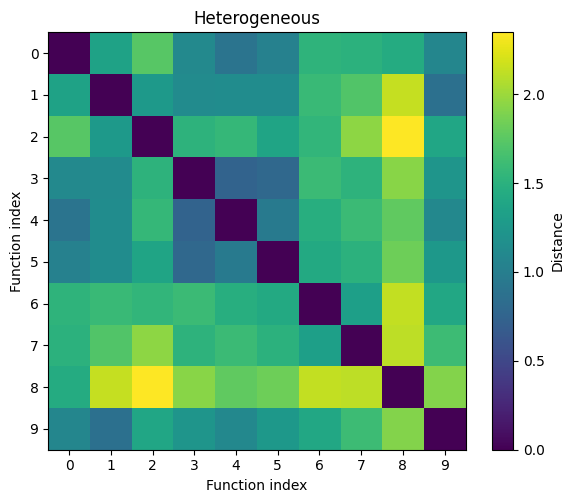

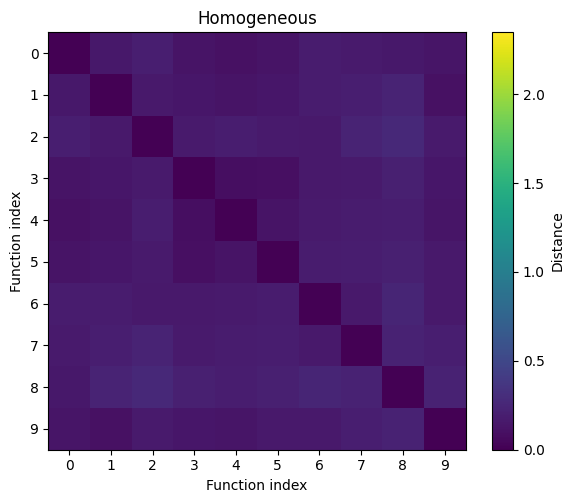

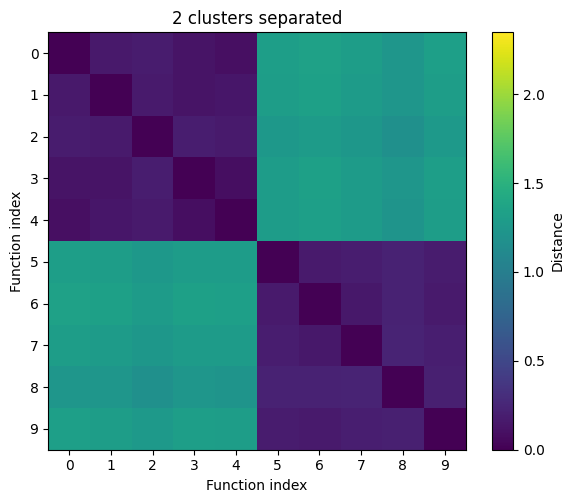

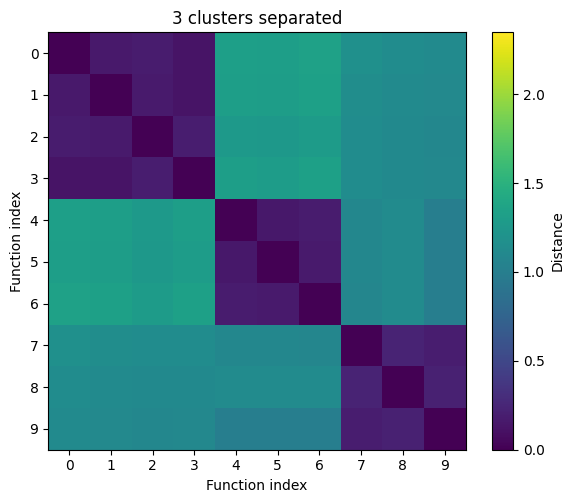

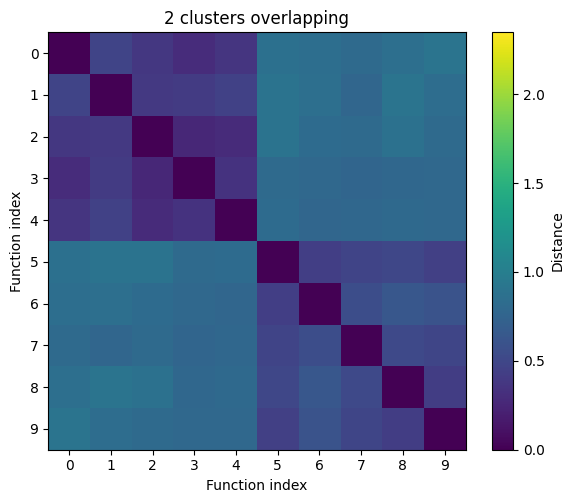

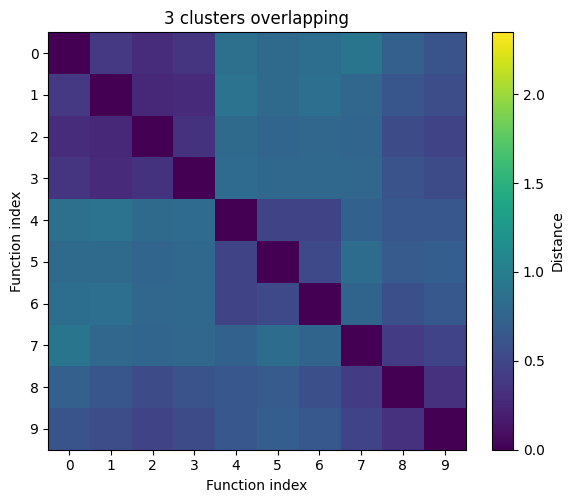

In [78]:
## Plotting the distance matrices for each dataset

max_distance = max(
    D.max() for D in distance_matrices.values()
)

for name, D in distance_matrices.items():
    fig, ax = plt.subplots(figsize=(6, 5))

    im = ax.imshow(
        D,
        cmap="viridis",
        vmin=0,
        vmax=max_distance
    )

    ax.set_title(name)
    ax.set_xlabel("Function index")
    ax.set_ylabel("Function index")

    ticks = np.arange(len(D))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)

    fig.colorbar(im, ax=ax, label="Distance")

    plt.tight_layout()
    plt.show()

In [79]:
def classical_mds(D):
    n = len(D)

    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J

    eigenvalues, eigenvectors = np.linalg.eigh(B)

    indices = np.argsort(eigenvalues)[::-1][:2]
    values = np.maximum(eigenvalues[indices], 0)

    coordinates = eigenvectors[:, indices] * np.sqrt(values)

    return coordinates

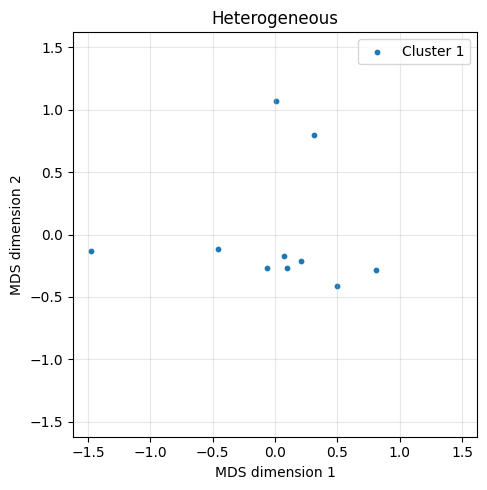

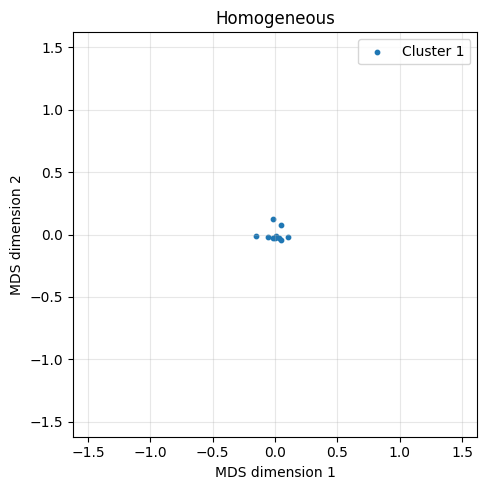

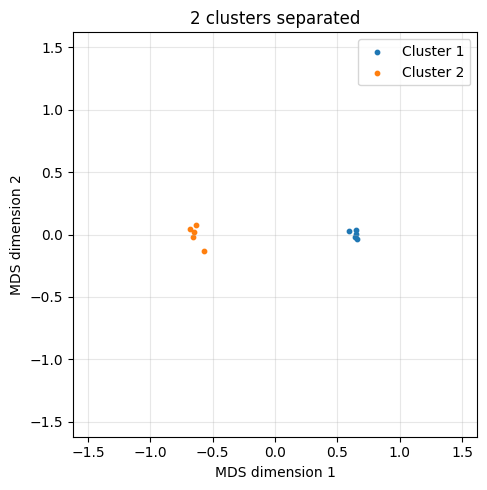

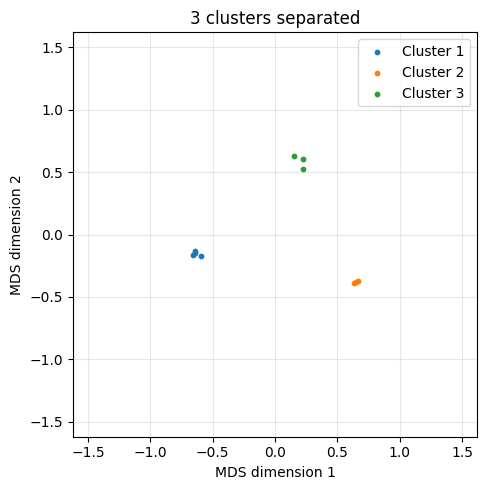

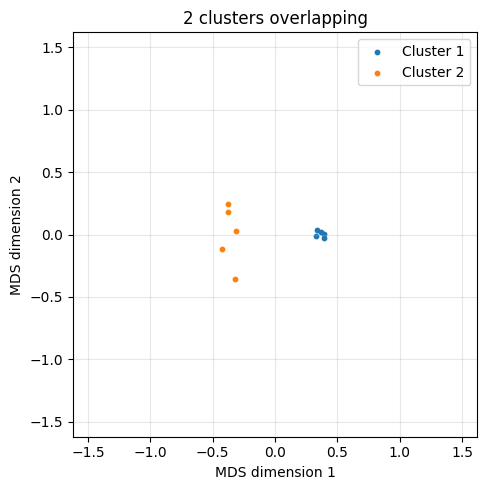

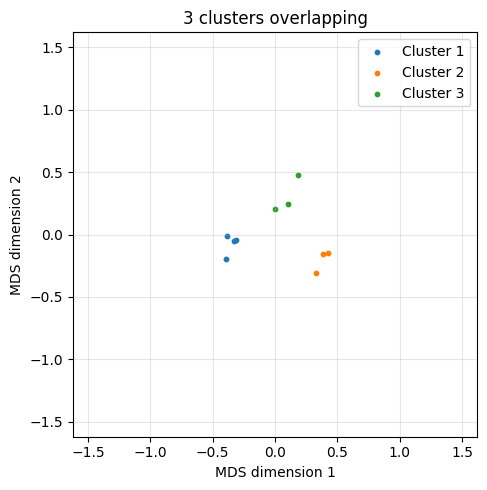

In [80]:
# Compute MDS coordinates for each dataset
mds_coordinates = {
    name: classical_mds(D)
    for name, D in distance_matrices.items()
}

# Common axis limits for comparison across datasets
axis_limit = 1.1 * max(
    np.max(np.abs(coordinates))
    for coordinates in mds_coordinates.values()
)

for name, _, _, labels, _, _ in datasets:
    coordinates = mds_coordinates[name]

    fig, ax = plt.subplots(figsize=(6, 5))

    for k in np.unique(labels):
        indices = labels == k

        ax.scatter(
            coordinates[indices, 0],
            coordinates[indices, 1],
            s=10,
            label=f"Cluster {k + 1}"
        )

    ax.set_title(name)
    ax.set_xlabel("MDS dimension 1")
    ax.set_ylabel("MDS dimension 2")

    ax.set_xlim(-axis_limit, axis_limit)
    ax.set_ylim(-axis_limit, axis_limit)
    ax.set_aspect("equal", adjustable="box")

    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()